# 04 · Beam-Based Alignment: orbit, DFS and WFS steering

A BPM reads the beam position relative to its own electrical centre, $b_i=x_i-o_i$, and the offsets $o_i$ are unknown. Steering $b_i\to0$ puts the beam through the BPM centres, not through the quadrupole centres. An off-centre quadrupole kicks particles of different energy by different angles, which creates dispersion and chromatic emittance growth; an off-centre accelerating structure creates intensity-dependent wakefield kicks.

| Term | Measured residual | Response matrix | SysID directory |
|---|---|---|---|
| Orbit | $\mathbf r_o=\mathbf b_0-\mathbf b_{ref}$ | $R_0$ | Orbit |
| DFS (dispersion-free steering) | $\mathbf r_d=(\mathbf b_E-\mathbf b_0)-\mathbf d_{target}$ | $R_D=R_E-R_0$ | Changed energy |
| WFS (wakefield-free steering) | $\mathbf r_w=\mathbf b_Q-\mathbf b_0$ | $R_W=R_Q-R_0$ | Changed intensity |

$\mathbf b_E-\mathbf b_0\approx\boldsymbol\eta\,\delta$ is the dispersion times the energy change. $\mathbf d_{target}=1000\,\boldsymbol\eta_{design}\,\delta$ (mm, with $\eta$ in m) comes from `interface.get_target_dispersion` and is zero unless the interface defines design dispersion at the BPMs.

**The orbit term holds the reference orbit, it does not steer to zero.** $\mathbf b_{ref}$ is the orbit measured at the first START; **Reset reference orbit** replaces it by the current orbit. The orbit weight therefore controls how far DFS and WFS may move the trajectory. To steer the orbit to chosen positions, use [Orbit Bump](03_OrbitBump.ipynb).

**Run:** follow [the setup guide](README.md), select the **Flight tutorials** kernel, then **Restart Kernel and Run All Cells**.

## Test setup

`Linac` is one transverse plane of 12 FODO cells (2 m drifts, $|k_1L|=0.6\ \mathrm{m^{-1}}$). Each cell has a corrector, an accelerating structure and a quadrupole with a BPM at its entrance. Quadrupoles, BPMs and structures have random 0.1 mm offsets; BPM noise is 2 µm. Energy is changed by $\delta=-5\,\%$ and the charge by $-20\,\%$. In the GUI, $R_0$, $R_E$ and $R_Q$ come from the three SysID directories.

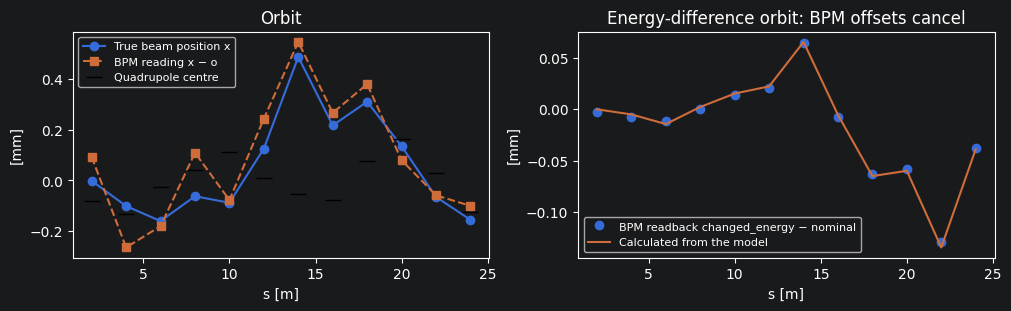

‖R0‖ = 26.9, ‖R_D‖ = 5.88, ‖R_W‖ = 1.25 (mm/mrad)


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from tutorial_support import Linac

delta_E, charge = -0.05, 0.8
machine = Linac(noise_mm=0.002)
R0 = machine.response()
RD = machine.response(delta=delta_E) - R0
RW = machine.response(charge=charge) - R0

def rms(values):
    return np.sqrt(np.mean(values**2))

def dispersion(m):
    return m.trajectory(delta=delta_E) - m.trajectory()

fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
axes[0].plot(machine.s, machine.trajectory(), 'o-', label='True beam position x')
axes[0].plot(machine.s, machine.bpms(), 's--', label='BPM reading x − o')
axes[0].plot(machine.s, machine.quad_offset, 'k_', ms=12, label='Quadrupole centre')
axes[0].set(xlabel='s [m]', ylabel='[mm]', title='Orbit')
axes[0].legend(fontsize=8)
axes[1].plot(machine.s, machine.bpms(delta=delta_E) - machine.bpms(), 'o', label='BPM readback changed_energy − nominal')
axes[1].plot(machine.s, dispersion(machine), '-', label='Calculated from the model')
axes[1].set(xlabel='s [m]', ylabel='[mm]', title='Energy-difference orbit: BPM offsets cancel')
axes[1].legend(fontsize=8)
plt.show()
print(f'‖R0‖ = {np.linalg.norm(R0):.1f}, ‖R_D‖ = {np.linalg.norm(RD):.2f}, ‖R_W‖ = {np.linalg.norm(RW):.2f} (mm/mrad)')

## Steering the BPMs to zero does not remove dispersion

One-to-one steering, $\Delta\mathbf c=-R_0^+\mathbf b_0$, zeroes the BPM readings, but the beam then follows the BPM offsets and still crosses the quadrupoles off-centre.

In [2]:
steered = Linac(noise_mm=0.002)
steered.settings = -np.linalg.pinv(R0, rcond=1e-3) @ steered.bpms()
print(f'BPM readings RMS:  {rms(machine.bpms()):.3f} -> {rms(steered.bpms()):.3f} mm')
print(f'Dispersion RMS:    {rms(dispersion(machine)):.4f} -> {rms(dispersion(steered)):.4f} mm')

BPM readings RMS:  0.245 -> 0.003 mm
Dispersion RMS:    0.0524 -> 0.0258 mm


## The correction BBA computes

Each iteration of BBA measures the nominal orbit, the orbit at changed energy and the orbit at changed intensity (resetting the beam after each), and stacks only the terms with a non-zero weight:
$$A=\begin{pmatrix}w_o R_0\\ w_d R_D\\ w_w R_W\end{pmatrix},\qquad \mathbf r=\begin{pmatrix}w_o\mathbf r_o\\ w_d\mathbf r_d\\ w_w\mathbf r_w\end{pmatrix},\qquad \Delta\mathbf c=-g\,A^+\mathbf r\quad\text{or}\quad -g\,(A^TA+\beta I)^{-1}A^T\mathbf r .$$
This minimizes $w_o^2\|\mathbf r_o\|^2+w_d^2\|\mathbf r_d\|^2+w_w^2\|\mathbf r_w\|^2$ after the step. Per-BPM weights (double-click a BPM) multiply the corresponding rows by $\sqrt{w_{BPM}}$. The new settings are clipped to ±**Max strength**. Before every step the GUI stops if a corrector readback differs from its set point by more than 0.05, and it stops when the transmission falls below the **Transmission threshold**.

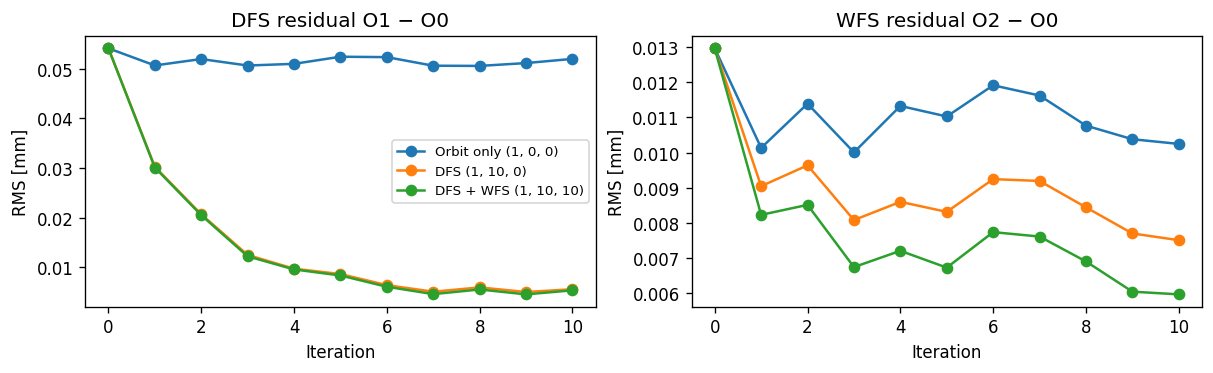

In [3]:
def bba(wo, wd, ww, gain=0.4, iterations=10, rcond=1e-3, limit=1.0):
    m = Linac(noise_mm=0.002)
    A = np.vstack([wo * R0, wd * RD, ww * RW])
    reference = m.bpms()
    history = []
    for iteration in range(iterations + 1):
        b0 = m.bpms()
        bE, bQ = m.bpms(delta=delta_E), m.bpms(charge=charge)
        history.append([rms(b0 - reference), rms(bE - b0), rms(bQ - b0)])
        if iteration < iterations:
            r = np.concatenate([wo * (b0 - reference), wd * (bE - b0), ww * (bQ - b0)])
            m.settings = np.clip(m.settings - gain * np.linalg.pinv(A, rcond=rcond) @ r, -limit, limit)
    return np.array(history), m

cases = {'Orbit only (1, 0, 0)': (1, 0, 0), 'DFS (1, 10, 0)': (1, 10, 0), 'DFS + WFS (1, 10, 10)': (1, 10, 10)}
fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
for label, weights in cases.items():
    history, _ = bba(*weights)
    for ax, values in zip(axes, history[:, 1:].T):
        ax.plot(values, 'o-', label=label)
for ax, title in zip(axes, ['DFS residual O1 − O0', 'WFS residual O2 − O0']):
    ax.set(xlabel='Iteration', ylabel='RMS [mm]', title=title)
axes[0].legend(fontsize=8)
plt.show()

With orbit weight only, nothing happens: the orbit already equals the reference. DFS removes most of the dispersion at the price of moving the trajectory by about 0.1 mm. Adding WFS reduces the intensity-dependent orbit as well.

## Choosing the parameters

| GUI field | Default | How to choose |
|---|---|---|
| Trajectory / DFS / WFS response directories | – | SysID directories in *Orbit*, *Changed energy* and *Changed intensity* mode. DFS and WFS need their directory only when their weight is > 0. |
| Change energy / intensity: Nominal, Test, Method | interface values | The same settings as in the SysID scan. |
| Orbit weight $w_o$ | 1 | Larger keeps the trajectory closer to the reference. |
| Dispersion weight $w_d$ | 10 | Put more weight for correcting dispersion. |
| Wakefield weight $w_w$ | 10 | Put more weight for correcting wakefields. |
| PINV tolerance | $10^{-3}$ | Connected to singular values of $A$; raise it if the kicks are large and noisy. |
| Beta parameter | 0 | 0 uses the pseudoinverse, otherwise prevents correctors from kicking too strong.|
| Gain $g$ / Number of iterations $n$ | 0.4 / 10 | Describes how much of computed correction is applied to the machine. 0.4 by default is a safety choice. / Number of algorithm iterations. |
| Transmission threshold | 0.65 | Fraction of the charge measured at the first iteration on the interface's chosen ICT; the correction stops below it. |
| Max strength H/V | interface value or $1.15\max|c|$ | Absolute corrector limits; 0 means no limit. |
| BPM weights | 1, 1, 1 | Lower a noisy or unreliable BPM; 0 removes it from that term. |
| Force triangular matrix / Remove coupling | off | Triangular for linacs and transfer lines; remove coupling if $R_{xy}$, $R_{yx}$ are only noise. |

After a correction the GUI copies its nominal, energy and intensity states into the corresponding SysID directories as `BBA_…_ITER_<n>_<kind>.pkl`. The next response-matrix fit includes them.